# Description

Step 1 of the plan on #733: load 5-minute OHLCV bars for BTC and ETH and
clean them.

- Load the bars from the Binance monthly files (cached as parquet)
- Put the bars on a regular 5-minute grid and find the gaps
- Fill gaps of up to 3 bars, leave longer gaps empty and split the data
  into segments at each one, so later features and labels never span a gap
- Flag zero-volume bars and extreme returns (kept, not dropped)
- Summarize the data quality per coin

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import data_utils as dutil

## Config

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVAL = "5m"
START = "2020-01-01"
END = "2026-10-01"
# Fill gaps of up to 15 minutes, leave longer ones empty.
MAX_FILL_BARS = 3
# Flag a return if it is larger than 10 rolling stds over the past day.
VOL_WINDOW_BARS = 288
EXTREME_STD = 10.0

## Load and clean

In [3]:
raw = {}
clean = {}
for symbol in SYMBOLS:
    raw[symbol] = dutil.load_ohlcv(symbol, START, END, interval=INTERVAL)
    clean[symbol] = dutil.clean_bars(
        raw[symbol],
        interval=INTERVAL,
        max_fill_bars=MAX_FILL_BARS,
        vol_window_bars=VOL_WINDOW_BARS,
        extreme_std=EXTREME_STD,
    )
clean["BTCUSDT"].head()

,open,high,low,close,volume,ret,is_missing,is_filled,is_zero_volume,is_extreme,segment_id
open_time,,,,,,,,,,,
2020-01-01 00:00:00+00:00,7195.24,7196.25,7178.64,7179.78,95.509133,NaN,False,False,False,False,0
2020-01-01 00:05:00+00:00,7179.76,7191.77,7178.20,7191.07,59.365225,0.001572,False,False,False,False,0
2020-01-01 00:10:00+00:00,7193.15,7193.53,7180.24,7180.97,48.068510,-0.001405,False,False,False,False,0
2020-01-01 00:15:00+00:00,7180.97,7186.40,7177.35,7178.29,32.192929,-0.000373,False,False,False,False,0
2020-01-01 00:20:00+00:00,7177.71,7182.46,7175.47,7176.96,49.027397,-0.000185,False,False,False,False,0


## Data quality table

In [4]:
quality = pd.DataFrame(
    {
        symbol: dutil.compute_quality_table(
            raw[symbol], clean[symbol], interval=INTERVAL
        )
        for symbol in SYMBOLS
    }
)
quality

,BTCUSDT,ETHUSDT
start,2020-01-01 00:00:00+00:00,2020-01-01 00:00:00+00:00
end,2026-09-30 23:55:00+00:00,2026-09-30 23:55:00+00:00
n_grid_bars,709920,709920
n_raw_bars,709458,709458
n_duplicates,0,0
n_gaps,15,15
n_missing_bars,462,462
longest_gap,0 days 05:50:00,0 days 05:50:00
n_filled_bars,0,0
n_long_gaps,15,15


## Gaps

The longest gaps, with their length in bars.

In [5]:
gaps = dutil.find_gaps(raw["BTCUSDT"], interval=INTERVAL)
gaps.sort_values("n_bars", ascending=False).head(10)

,start,end,n_bars
1,2020-02-19 11:40:00+00:00,2020-02-19 17:25:00+00:00,70
11,2021-04-25 04:05:00+00:00,2021-04-25 08:40:00+00:00,56
12,2021-08-13 02:00:00+00:00,2021-08-13 06:25:00+00:00,54
6,2020-12-21 14:10:00+00:00,2020-12-21 17:55:00+00:00,46
4,2020-06-28 02:00:00+00:00,2020-06-28 05:25:00+00:00,42
3,2020-04-25 02:00:00+00:00,2020-04-25 04:25:00+00:00,30
10,2021-04-20 02:00:00+00:00,2021-04-20 04:25:00+00:00,30
2,2020-03-04 09:25:00+00:00,2020-03-04 11:25:00+00:00,25
13,2021-09-29 07:00:00+00:00,2021-09-29 08:55:00+00:00,24
9,2021-03-06 02:00:00+00:00,2021-03-06 03:25:00+00:00,18


Check if the two coins have their gaps at the same times.

In [6]:
gaps_eth = dutil.find_gaps(raw["ETHUSDT"], interval=INTERVAL)
print("Same gaps for BTC and ETH:", gaps.equals(gaps_eth))

Same gaps for BTC and ETH: True


## Flagged bars

Extreme returns per year. Most should come from known market events.

In [7]:
extreme_per_year = pd.DataFrame(
    {
        symbol: clean[symbol]["is_extreme"]
        .groupby(clean[symbol].index.year)
        .sum()
        for symbol in SYMBOLS
    }
)
extreme_per_year

,BTCUSDT,ETHUSDT
open_time,,
2020,65,36
2021,37,18
2022,62,46
2023,75,78
2024,30,35
2025,31,39
2026,25,37


In [8]:
# The largest moves among the flagged bars.
flagged = clean["BTCUSDT"].loc[clean["BTCUSDT"]["is_extreme"], ["close", "ret"]]
flagged.reindex(flagged["ret"].abs().sort_values(ascending=False).index).head(10)

,close,ret
open_time,,
2020-03-13 02:35:00+00:00,5222.12,0.184288
2020-03-12 10:55:00+00:00,6014.90,-0.102254
2021-09-07 15:05:00+00:00,43088.74,-0.098905
2021-05-19 13:05:00+00:00,30101.00,-0.096972
2023-08-17 21:40:00+00:00,25188.01,-0.086687
2020-05-10 00:15:00+00:00,8628.15,-0.076291
2021-05-19 12:50:00+00:00,32904.67,-0.073429
2025-10-10 21:15:00+00:00,103975.26,-0.073382
2021-04-18 03:30:00+00:00,52674.66,-0.066078


In [9]:
# Zero-volume bars per day.
zero_vol = clean["BTCUSDT"].index[clean["BTCUSDT"]["is_zero_volume"]]
zero_vol.to_series().dt.date.value_counts().sort_index()

open_time
2020-12-21    10
2021-01-11     1
2021-02-11    17
2023-03-24    14
Name: count, dtype: int64

## Plot

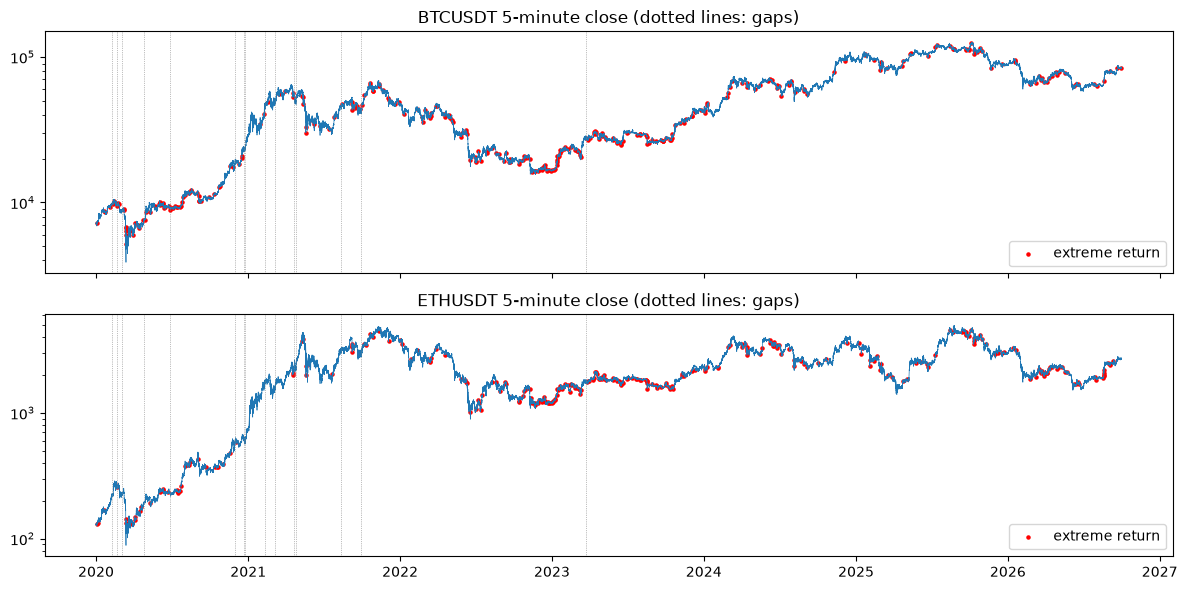

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, symbol in zip(axes, SYMBOLS):
    df = clean[symbol]
    ax.plot(df.index, df["close"], linewidth=0.5)
    flagged = df.index[df["is_extreme"]]
    ax.scatter(
        flagged,
        df.loc[flagged, "close"],
        color="red",
        s=5,
        label="extreme return",
    )
    gap_starts = dutil.find_gaps(raw[symbol], interval=INTERVAL)["start"]
    for gap_start in gap_starts:
        ax.axvline(gap_start, color="gray", linewidth=0.5, linestyle=":")
    ax.set_title(f"{symbol} 5-minute close (dotted lines: gaps)")
    ax.set_yscale("log")
    ax.legend()
plt.tight_layout()

## Observations

- The data is clean overall: no duplicates, and only 462 of 709,920 bars
  (0.07%) are missing for each coin
- BTC and ETH have the same 15 gaps at the same times, so these are Binance
  outages and maintenance, not problems with one coin. The longest is
  5h50m on 2020-02-19. Most are in 2020-2021, and the last one is on
  2023-03-24
- Every gap is at least 12 bars (1 hour) long, so nothing was filled. The
  data splits into 16 segments, and features and labels will be computed
  inside each one
- The 42 zero-volume bars are on 4 days, and on 3 of them they come right
  before a gap (2020-12-21, 2021-02-11, 2023-03-24). Trading stopped before
  the data stopped, so the prices in those bars are stale. For now they are
  only flagged; we may want to treat them as part of the gap
- About 300 bars per coin (0.05%) have an extreme return, more than 10
  times the past day's std. The largest ones are real crashes and
  rebounds: March 2020 (+18% in 5 minutes on 2020-03-13), the May 2021
  crash, and 2025-10-10. They are kept, since fat tails are part of what we
  study